# Predicting Student Final Exam Grades
### Decision Tree Regression, Random Forests, and a Confusion Matrix

**Our question:** Can we predict a student's final mathematics grade using their earlier grades and study habits?

By the end, we will:
1. Load and explore a real dataset.
2. Train a **decision tree regressor** with `max_depth=3`.
3. Evaluate its predictions with **MAE, RMSE, and R²**.
4. Draw the tree and inspect **feature importance**.
5. Compare it with a **random forest**.
6. Build a separate **pass/fail classifier** so we can see a **confusion matrix**.

> **Important:** Predicting an exact grade (e.g., 14.2/20) is **regression**. Predicting Pass or Fail is **classification**. A confusion matrix is for classification, not numeric regression.

**Dataset:** UCI [Student Performance](https://archive.ics.uci.edu/dataset/320/student+performance), mathematics course, 395 students. Grades range from **0 to 20**.

## 1. Import our tools

We only need a few standard Python data-science libraries. If something is missing, install it in a notebook cell with:

`%pip install pandas numpy matplotlib scikit-learn`

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, ConfusionMatrixDisplay
)

## 2. Load the real student data

The file uses **semicolons** (`;`) between columns, not commas.

- If you have `student-mat.csv` next to this notebook, it will use that file.
- Otherwise, it downloads the same dataset from a public GitHub mirror of the UCI data. **Internet is needed for the first download.**


In [2]:
# Direct CSV mirror of the UCI mathematics dataset.
url = "https://raw.githubusercontent.com/rupakc/UCI-Data-Analysis/master/Student%20Dataset/Student/student-mat.csv"

try:
    students = pd.read_csv("student-mat.csv", sep=";")
    print("Loaded student-mat.csv from this folder.")
except FileNotFoundError:
    students = pd.read_csv(url, sep=";")
    print("Downloaded the UCI student dataset.")

print("Students:", len(students))
students.head().T

Downloaded the UCI student dataset.
Students: 395


,0,1,2,3,4
school,GP,GP,GP,GP,GP
sex,F,F,F,F,F
age,18,17,15,15,16
address,U,U,U,U,U
famsize,GT3,GT3,LE3,GT3,GT3
Pstatus,A,T,T,T,T
Medu,4,1,1,4,3
Fedu,4,1,1,2,3
Mjob,at_home,at_home,at_home,health,other
Fjob,teacher,other,other,services,other


## 3. What are we predicting?

Our target is **`G3`**, the final mathematics grade (**0–20**).

Here is the distribution of those grades. Each bar shows how many students received a particular grade.

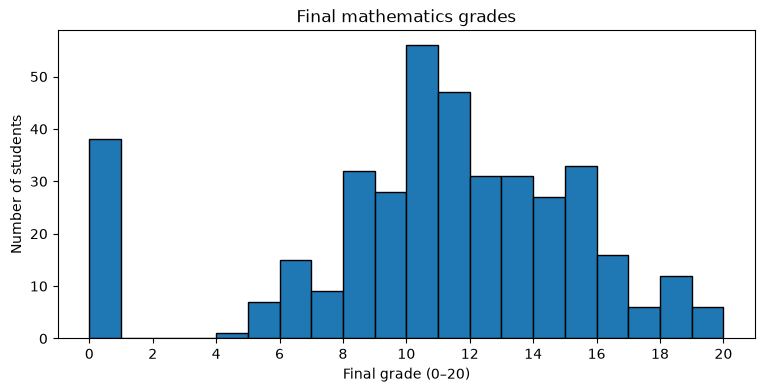

In [3]:
# See how the final grades are distributed.
plt.figure(figsize=(9, 4))
plt.hist(students["G3"], bins=20, edgecolor="black")
plt.title("Final mathematics grades")
plt.xlabel("Final grade (0–20)")
plt.ylabel("Number of students")
plt.xticks(range(0, 21, 2))
plt.show()

array([[<Axes: title={'center': 'final_grade_zero_to_onehundred'}>]],
      dtype=object)

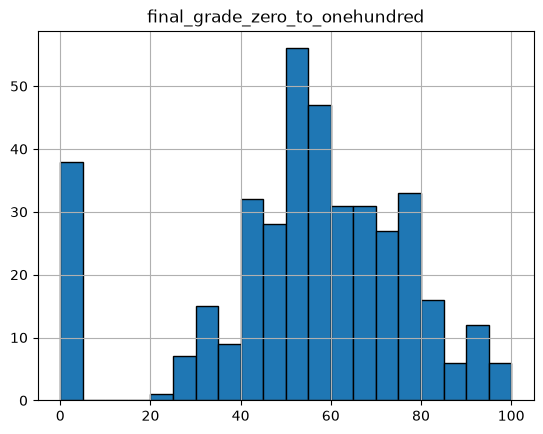

In [4]:
students["final_grade_zero_to_onehundred"] = students["G3"] * 5
students.hist(column="final_grade_zero_to_onehundred",bins=20, edgecolor="black")

## 4. Choose Features [link](https://archive.ics.uci.edu/dataset/320/student+performance) to data dictionary and meaning of every column.

We'll keep it simple with **7 numeric columns**:

| Column | Meaning |
|---|---|
| `G1` | First grading-period grade (0–20) |
| `G2` | Second grading-period grade (0–20) |
| `studytime` | Weekly study time (1 = least, 4 = most) |
| `failures` | Number of past class failures |
| `absences` | Number of school absences |
| `goout` | Frequency of going out with friends (1–5) |
| `freetime` | Amount of free time after school (1–5) |

We use `G1` and `G2` because they are available **before** the final grade. If we wanted to predict **at the start of the year**, we would need to remove them.

### All columns and information here. 

In [5]:
students.head().T

,0,1,2,3,4
school,GP,GP,GP,GP,GP
sex,F,F,F,F,F
age,18,17,15,15,16
address,U,U,U,U,U
famsize,GT3,GT3,LE3,GT3,GT3
Pstatus,A,T,T,T,T
Medu,4,1,1,4,3
Fedu,4,1,1,2,3
Mjob,at_home,at_home,at_home,health,other
Fjob,teacher,other,other,services,other


In [6]:
students.school.value_counts()

school
GP    349
MS     46
Name: count, dtype: int64

In [7]:
students.columns

Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
       'Walc', 'health', 'absences', 'G1', 'G2', 'G3',
       'final_grade_zero_to_onehundred'],
      dtype='str')

In [8]:


# X = information we use to make predictions.
features = ["G1", "G2", "studytime", "failures", "absences", "goout", "freetime"]
# features = ["studytime", "failures", "absences", "goout", "freetime"]

X = students[features]

# y = the correct answer we want to predict.
y = students["G3"]

# Check for missing values before training.
print("Missing values per feature:")
print(X.isna().sum())

X.head()

Missing values per feature:
G1           0
G2           0
studytime    0
failures     0
absences     0
goout        0
freetime     0
dtype: int64


,G1,G2,studytime,failures,absences,goout,freetime
0,5,6,2,0,6,4,3
1,5,5,2,0,4,3,3
2,7,8,2,3,10,2,3
3,15,14,3,0,2,2,2
4,6,10,2,0,4,2,3


## 5. Split students into training and test sets

- **80% training:** Our model learns from these students.
- **20% testing:** Students the model hasn't seen while learning.

`random_state=42` makes the split repeatable, so everyone in class gets the same result.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training students:", len(X_train))
print("Testing students:", len(X_test))

Training students: 316
Testing students: 79


## 6. Train our decision tree regressor

A **regression tree** predicts a *number*. Each split asks a yes/no question about one feature.

`max_depth=3` keeps the tree small enough to draw and explain.

In [10]:
# Make a small tree with at most 3 levels of questions.
tree = DecisionTreeRegressor(max_depth=3, random_state=42)

# The model learns only from the training students.
tree.fit(X_train, y_train)

# Predict final grades for unseen students.
tree_predictions = tree.predict(X_test)

# Look at some real grades vs. predicted grades.
comparison = pd.DataFrame({
    "Actual grade": y_test.to_numpy(),
    "Predicted grade": np.round(tree_predictions, 1)
})
comparison.head(10)

,Actual grade,Predicted grade
0,10,9.4
1,12,11.5
2,5,6.6
3,10,9.4
4,9,9.4
5,13,13.0
6,18,18.3
7,6,6.6
8,0,6.5
9,14,13.0


## 7. Draw the whole tree

**How to read it:**
- Start at the **top** node.
- If the condition is **True**, go **left**; otherwise go **right**.
- `samples` = number of *training* students in that node.
- `value` = average final grade of those training students. That's the prediction at a leaf!

The tree below has at most **3 splits from root to leaf**.

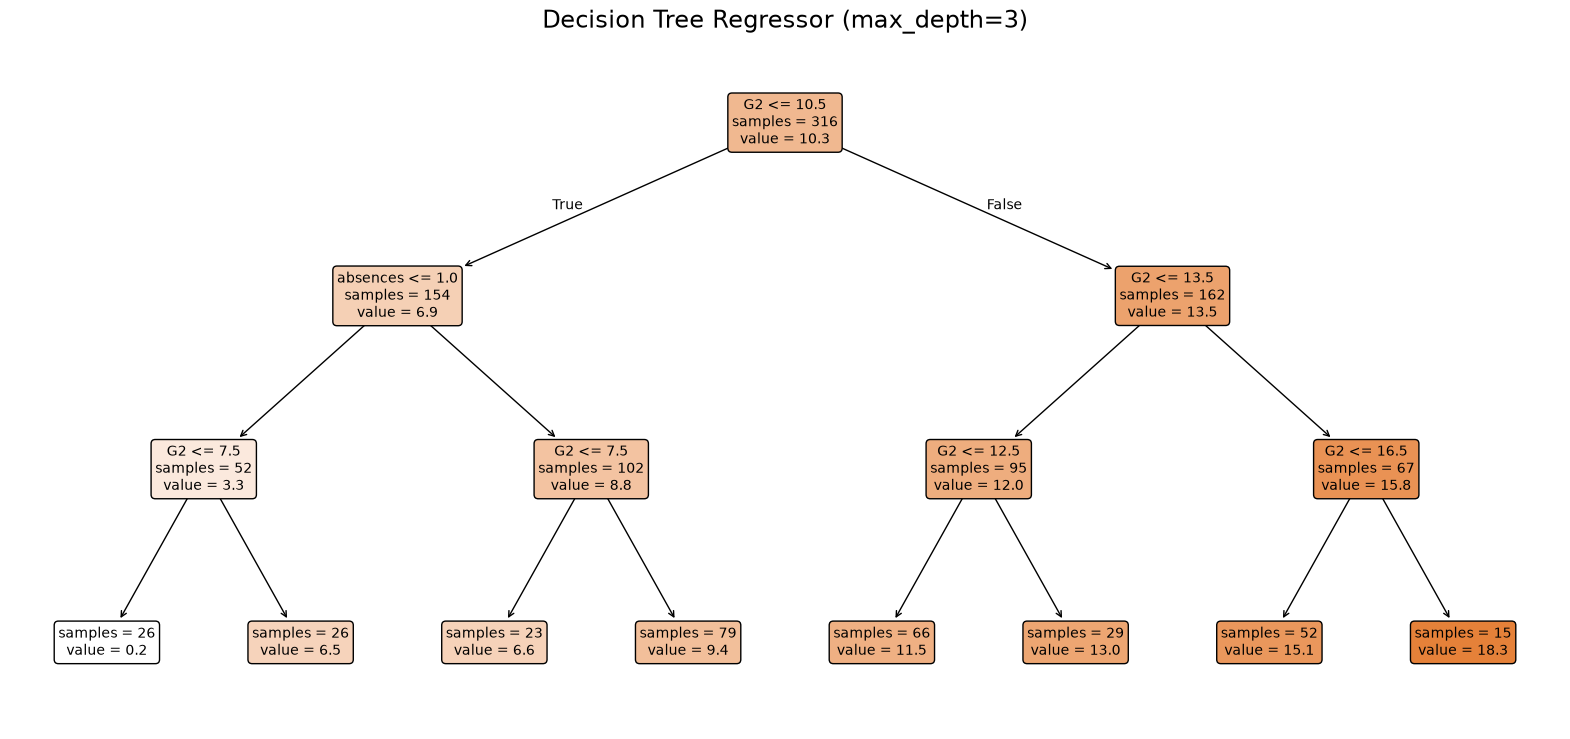

In [11]:
plt.figure(figsize=(20, 9))

plot_tree(
    tree,
    feature_names=features,
    filled=True,
    rounded=True,
    impurity=False,  # Hide the MSE formula to keep labels clean.
    precision=1,
    fontsize=10
)

plt.title("Decision Tree Regressor (max_depth=3)", fontsize=17)
plt.show()

## 8. Evaluate the predictions

We use **regression metrics**, because our output is a number.

- **MAE (mean absolute error):** On average, how many grade points are we off? **Lower is better.**
- **RMSE (root mean squared error):** Similar, but it penalizes big misses more. **Lower is better.**
- **R²:** How much better are we than always predicting the average grade? **1 is perfect; 0 is roughly equal to the average-grade baseline; negative is worse.**

Let's compare our tree with a very simple baseline that always predicts the average *training* grade.

In [12]:
# Baseline: always predict the average training grade.
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
baseline_predictions = baseline.predict(X_test)

# How wrong is our simple baseline?
baseline_mae = mean_absolute_error(y_test, baseline_predictions)

# How wrong is our decision tree?
tree_mae = mean_absolute_error(y_test, tree_predictions)
tree_rmse = np.sqrt(mean_squared_error(y_test, tree_predictions))
tree_r2 = r2_score(y_test, tree_predictions)

print(f"Baseline MAE: {baseline_mae:.2f} grade points")
print(f"Tree MAE:     {tree_mae:.2f} grade points")
print(f"Tree RMSE:    {tree_rmse:.2f} grade points")
print(f"Tree R²:      {tree_r2:.2f}")

Baseline MAE: 3.65 grade points
Tree MAE:     1.31 grade points
Tree RMSE:    2.17 grade points
Tree R²:      0.77


### Actual grade vs. predicted grade

If predictions were perfect, every dot would lie on the dashed diagonal line. Dots farther away mean bigger errors.

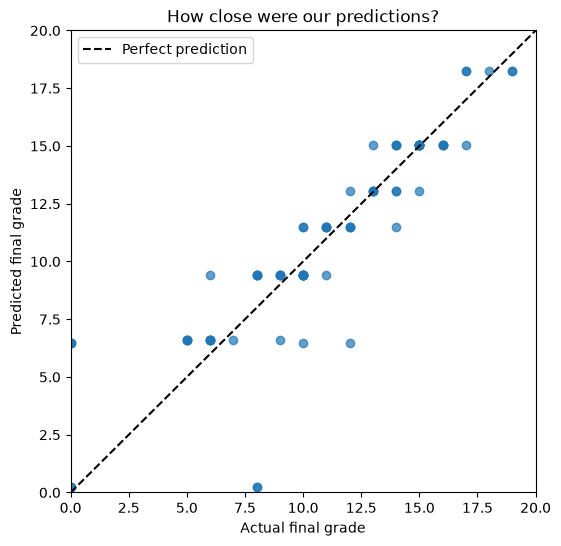

In [13]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, tree_predictions, alpha=0.7)
plt.plot([0, 20], [0, 20], "k--", label="Perfect prediction")
plt.xlim(0, 20)
plt.ylim(0, 20)
plt.xlabel("Actual final grade")
plt.ylabel("Predicted final grade")
plt.title("How close were our predictions?")
plt.legend()
plt.show()

## 9. Which features mattered most?

**Feature importance** measures how much each feature helped the tree reduce prediction error in its *training data*.

These scores add up to **1.0**. A high score means the tree used that feature to make useful splits. **It does not prove causation.**

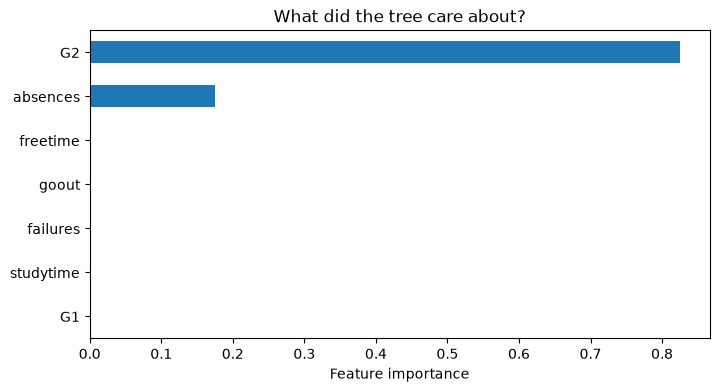

G2           0.825
absences     0.175
G1           0.000
studytime    0.000
failures     0.000
goout        0.000
freetime     0.000
dtype: float64


In [14]:
# Pair every feature name with its importance score.
importance = pd.Series(tree.feature_importances_, index=features)

# Put the largest importance at the top of the chart.
importance = importance.sort_values()

plt.figure(figsize=(8, 4))
importance.plot(kind="barh")
plt.xlabel("Feature importance")
plt.title("What did the tree care about?")
plt.show()

print(importance.sort_values(ascending=False).round(3))

## 10. Bonus: try a Random Forest Regressor

A **random forest** averages predictions from many different decision trees. It is often more accurate than one tiny tree, but harder to draw.

We'll try **100 trees** and compare the errors on the *same test students*.

In [15]:
# A forest of 100 trees, rather than one tree of depth 3.
forest = RandomForestRegressor(n_estimators=100, random_state=42)
forest.fit(X_train, y_train)
forest_predictions = forest.predict(X_test)

forest_mae = mean_absolute_error(y_test, forest_predictions)
forest_rmse = np.sqrt(mean_squared_error(y_test, forest_predictions))
forest_r2 = r2_score(y_test, forest_predictions)

# How wrong is our decision tree?
print(f"Baseline MAE: {baseline_mae:.2f} grade points")
print('/'*33)
print(f"Tree MAE:     {tree_mae:.2f} grade points")
print(f"Tree RMSE:    {tree_rmse:.2f} grade points")
print(f"Tree R²:      {tree_r2:.2f}")


print('/'*33)
print(f"Random forest MAE:  {forest_mae:.2f}")
print(f"Random forest RMSE: {forest_rmse:.2f}")
print(f"Random forest R²:   {forest_r2:.2f}")

Baseline MAE: 3.65 grade points
/////////////////////////////////
Tree MAE:     1.31 grade points
Tree RMSE:    2.17 grade points
Tree R²:      0.77
/////////////////////////////////
Random forest MAE:  1.13
Random forest RMSE: 1.71
Random forest R²:   0.86


## 11. Confusion matrix: a **different** problem (Pass vs. Fail)

A confusion matrix cannot directly evaluate predictions like **12.7/20**. It needs **categories**.

So let's create a **separate decision tree classifier**, also with `max_depth=3`:

- **Fail (0):** Final grade below 10.
- **Pass (1):** Final grade 10 or higher.

We use the *same features and the same train/test split*, but now train the model to predict **Pass or Fail**, not an exact grade.

# Okay.  So G2 is by far the most important factor to determining G3.  But thats obvious....  Tell me something more interesting. 
### Remove G1 and G2, and try using interesting features like "Walc" weekend alcohol consumption. "
### Full list of features [see the data dict](https://archive.ics.uci.edu/dataset/320/student+performance)

# Student that comes up with the MOST INTERESTING finding gets a FULL WEEK homework pass and letter of rec from me. 
Some interesting features:
* "absences" - number of school absences (numeric: from 0 to 93)
* "Walc" - weekend alcohol consumption (numeric: from 1 - very low to 5 - very high)
* "goout" - going out with friends (numeric: from 1 - very low to 5 - very high)
* "reason" - reason to choose this school (nominal: close to 'home', school 'reputation', 'course' preference or 'other')


---
# 12. My question: does outside prep keep students from quitting?

**Why I picked this.** As a CS student, I see a gap between what school teaches and what actually gets you a job. Classes are theory, but interviews ask for LeetCode, system design, and AI tools. So many of us prep *outside* school (programs like CTP, bootcamps, LeetCode). I wanted to see if this dataset shows anything similar.

This data is about high school math students in Portugal, not CS students. But it has two columns that match my question:
* **`paid`**: does the student pay for **extra classes outside school**? (my "outside prep")
* **`schoolsup`**: does the student get **extra help from the school itself**?

**Plan:**
1. First, remove G1 and G2 and see what predicts the final grade without them.
2. Compare students with and without outside classes.
3. Check whether the result holds for every kind of student.
4. The twist: does school help really hurt grades?

## 12.1 What predicts the final grade WITHOUT G1 and G2?
G1 and G2 are just earlier grades, so of course they predict G3. Let's remove them and give the model **every other column** (study habits, family, alcohol, going out, etc.).

Text columns like `paid` (yes/no) have to become numbers first. `pd.get_dummies` turns each one into a 0/1 column. `drop_first=True` keeps one column per yes/no question instead of two.

In [16]:
# Every column except the grades (G1, G2, G3) and the 0-100 version of G3 we made above
non_grade = students.drop(columns=["G1", "G2", "G3", "final_grade_zero_to_onehundred"])

# Turn text columns (yes/no, school name, etc.) into 0/1 number columns
X_no_grades = pd.get_dummies(non_grade, drop_first=True, dtype=int)
y_no_grades = students["G3"]

# Same 80/20 split and random_state as before so the comparison is fair
X_ng_train, X_ng_test, y_ng_train, y_ng_test = train_test_split(
    X_no_grades, y_no_grades, test_size=0.20, random_state=42
)

# Small tree (depth 3) and a random forest, same as earlier in the notebook
tree_ng = DecisionTreeRegressor(max_depth=3, random_state=42).fit(X_ng_train, y_ng_train)
forest_ng = RandomForestRegressor(n_estimators=300, random_state=42).fit(X_ng_train, y_ng_train)

for name, model in [("Tree (depth 3)", tree_ng), ("Random forest", forest_ng)]:
    pred = model.predict(X_ng_test)
    print(f"{name:15} R²: {r2_score(y_ng_test, pred):.2f}   MAE: {mean_absolute_error(y_ng_test, pred):.2f} grade points")

Tree (depth 3)  R²: 0.05   MAE: 3.55 grade points
Random forest   R²: 0.27   MAE: 3.07 grade points


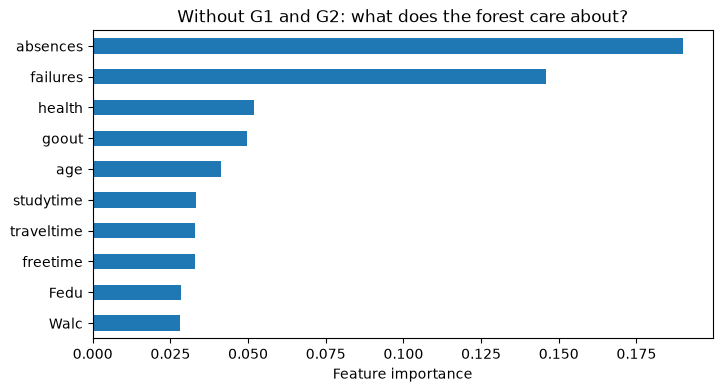

absences      0.190
failures      0.146
health        0.052
goout         0.050
age           0.041
studytime     0.033
traveltime    0.033
freetime      0.033
Fedu          0.028
Walc          0.028
dtype: float64


In [17]:
# Which features did the forest rely on most?
importance_ng = pd.Series(forest_ng.feature_importances_, index=X_no_grades.columns)
top10 = importance_ng.sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 4))
top10.sort_values().plot(kind="barh")
plt.xlabel("Feature importance")
plt.title("Without G1 and G2: what does the forest care about?")
plt.show()

print(top10.round(3))

In [18]:
# Why is 'absences' the top feature? Look at the students who ended with a 0.
students["ended_with_zero"] = students["G3"] == 0

print("Students who ended with a 0:", students["ended_with_zero"].sum())
print("Average absences, students who ended with 0:", round(students.loc[students["ended_with_zero"], "absences"].mean(), 2))
print("Average absences, everyone else:            ", round(students.loc[~students["ended_with_zero"], "absences"].mean(), 2))

Students who ended with a 0: 38
Average absences, students who ended with 0: 0.0
Average absences, everyone else:             6.32


**What this shows:**
* Without past grades, the models do much worse. The forest's R² drops to about **0.27** (the forest scored 0.86 with G1 and G2), and the small tree barely beats guessing the average. Predicting a grade from habits alone is hard.
* **`absences`** and **`failures`** (past failed classes) matter most.
* ⚠️ **A data trap:** every student who ended with a **0** has **exactly 0 absences** recorded. These students most likely stopped coming to class or skipped the final, so nobody recorded absences. The model partly learns "0 absences → final grade 0", which is the opposite of what you'd expect. **Feature importance tells you what the model used, not what causes good grades.**

That is why I'm looking at the students who **ended with a 0** (gave up or didn't take the final) as a separate outcome.

## 12.2 Outside classes vs. the final grade
Compare students who pay for extra classes outside school (`paid = yes`) with students who don't. Three questions:
* Did they **start** at the same level? (G1 = first-term grade)
* How did they **finish**? (G3 average)
* How many **ended with a 0**?

In [19]:
paid_summary = students.groupby("paid").agg(
    students=("G3", "size"),
    avg_first_term_G1=("G1", "mean"),
    avg_final_G3=("G3", "mean"),
    pct_ended_with_zero=("ended_with_zero", "mean"),
)
paid_summary["pct_ended_with_zero"] = (paid_summary["pct_ended_with_zero"] * 100).round(1)
paid_summary.round(2)

,students,avg_first_term_G1,avg_final_G3,pct_ended_with_zero
paid,,,,
no,214,10.79,9.99,14.0
yes,181,11.05,10.92,4.4


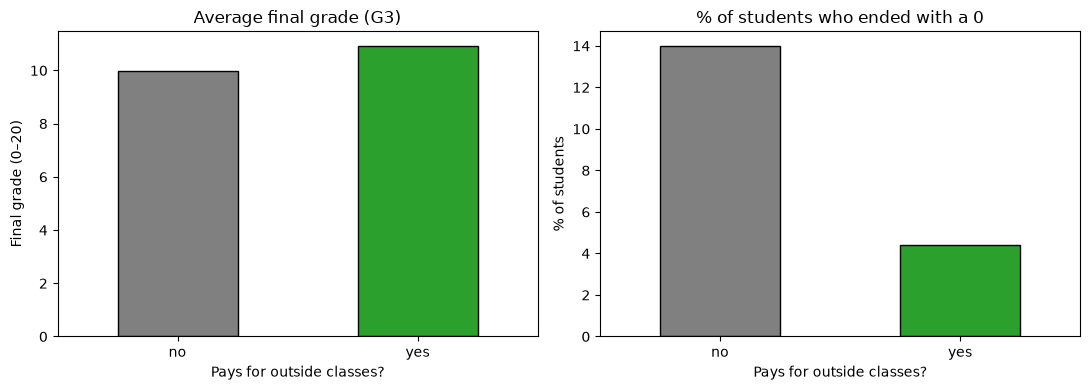

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

paid_summary["avg_final_G3"].plot(kind="bar", ax=axes[0], color=["gray", "tab:green"], edgecolor="black")
axes[0].set_title("Average final grade (G3)")
axes[0].set_xlabel("Pays for outside classes?")
axes[0].set_ylabel("Final grade (0–20)")
axes[0].tick_params(axis="x", rotation=0)

paid_summary["pct_ended_with_zero"].plot(kind="bar", ax=axes[1], color=["gray", "tab:green"], edgecolor="black")
axes[1].set_title("% of students who ended with a 0")
axes[1].set_xlabel("Pays for outside classes?")
axes[1].set_ylabel("% of students")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

**Is the difference real, or just luck?** A **p-value** answers: *if outside classes made no difference at all, how likely would we be to see a gap this big just by chance?* Under **0.05** is the usual cutoff for "probably real".
* For the **average grade** we use a Mann-Whitney test (compares two groups of numbers).
* For **ended with a 0** (yes/no counts) we use a chi-square test.

In [21]:
from scipy.stats import mannwhitneyu, chi2_contingency, fisher_exact

paid_yes = students[students["paid"] == "yes"]
paid_no = students[students["paid"] == "no"]

grade_p = mannwhitneyu(paid_yes["G3"], paid_no["G3"]).pvalue
zero_table = pd.crosstab(students["paid"], students["ended_with_zero"])
zero_p = chi2_contingency(zero_table)[1]

print(zero_table, "\n")
print(f"p-value, average final grade: {grade_p:.3f}")
print(f"p-value, ended with a 0:      {zero_p:.4f}")

ended_with_zero  False  True 
paid                         
no                 184     30
yes                173      8 

p-value, average final grade: 0.227
p-value, ended with a 0:      0.0023


**What this shows:** both groups **started at about the same level** (G1 ≈ 11). At the end, their **average grades are close**, and that gap could be chance (p ≈ 0.23). But students **without** outside classes were about **3.5× more likely to end with a 0** (14% vs 4%), and that gap is very unlikely to be chance (p ≈ 0.002).

So outside classes don't seem to make students score higher. They seem to keep students **from giving up**.

## 12.3 Does this hold for every kind of student?
Students who take outside classes also had **fewer past failures**. Maybe that alone explains it. Let's split the students into two groups, **no past failures** and **1+ past failures**, and compare inside each group.

In [22]:
students["past_failures"] = students["failures"].apply(lambda f: "0 past failures" if f == 0 else "1+ past failures")

by_failures = students.groupby(["past_failures", "paid"]).agg(
    students=("G3", "size"),
    ended_with_zero=("ended_with_zero", "sum"),
    pct_ended_with_zero=("ended_with_zero", "mean"),
)
by_failures["pct_ended_with_zero"] = (by_failures["pct_ended_with_zero"] * 100).round(1)
by_failures

students  ended_with_zero  pct_ended_with_zero
past_failures    paid                                                
0 past failures  no         153               11                  7.2
                 yes        159                7                  4.4
1+ past failures no          61               19                 31.1
                 yes         22                1                  4.5

0 past failures   p-value: 0.3374
1+ past failures  p-value: 0.0176


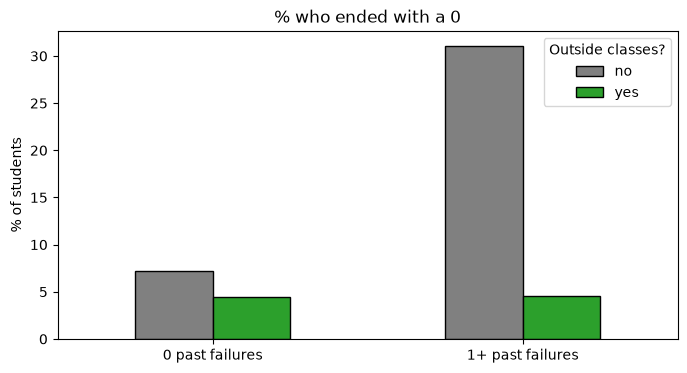

In [23]:
# Test each group separately. Fisher's exact test works better than chi-square for small groups.
for group in ["0 past failures", "1+ past failures"]:
    subset = students[students["past_failures"] == group]
    table = pd.crosstab(subset["paid"], subset["ended_with_zero"])
    print(f"{group:17} p-value: {fisher_exact(table)[1]:.4f}")

# Chart: % ended with a 0, by past failures and outside classes
by_failures["pct_ended_with_zero"].unstack().plot(kind="bar", figsize=(8, 4), color=["gray", "tab:green"], edgecolor="black")
plt.title("% who ended with a 0")
plt.ylabel("% of students")
plt.xlabel("")
plt.xticks(rotation=0)
plt.legend(title="Outside classes?")
plt.show()

**This is my main finding.**
* For students with **no past failures**, outside classes make only a small difference (about 7% vs 4%), and it could be chance.
* For students who **already failed a class before**, the difference is huge: **31% of them ended with a 0 without outside classes, vs about 5% with them** (1 out of 22), p ≈ 0.02.

So outside prep matters most for the students who are **already struggling**.

⚠️ **Limits:** only 22 students are in the "past failures + outside classes" group, which is small. This is also **correlation, not causation**: families who pay for classes may support their kids in other ways too. The data can't separate those.

## 12.4 The twist: does school help hurt grades?
Now the other kind of help, extra support from the **school itself** (`schoolsup`).

           students  avg_first_term_G1  avg_final_G3
schoolsup                                           
no              344              11.18         10.56
yes              51               9.08          9.43 

p-value, final grade: 0.003


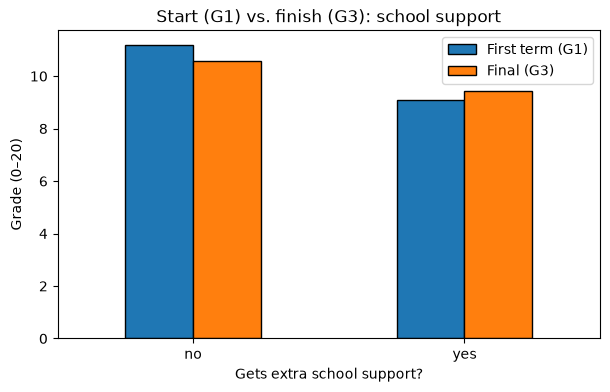

In [24]:
school_summary = students.groupby("schoolsup").agg(
    students=("G3", "size"),
    avg_first_term_G1=("G1", "mean"),
    avg_final_G3=("G3", "mean"),
)
print(school_summary.round(2), "\n")

support_yes = students[students["schoolsup"] == "yes"]
support_no = students[students["schoolsup"] == "no"]
print(f"p-value, final grade: {mannwhitneyu(support_yes['G3'], support_no['G3']).pvalue:.3f}")

# Start vs. finish for each group
school_summary[["avg_first_term_G1", "avg_final_G3"]].plot(kind="bar", figsize=(7, 4), edgecolor="black")
plt.title("Start (G1) vs. finish (G3): school support")
plt.ylabel("Grade (0–20)")
plt.xlabel("Gets extra school support?")
plt.xticks(rotation=0)
plt.legend(["First term (G1)", "Final (G3)"])
plt.show()

**What this shows:** students who get school support **finish lower**, and that gap is real (p ≈ 0.003). A careless reading says "school support hurts grades."

But look at the start: they were **already about 2 points behind in the first term** (G1 ≈ 9.1 vs 11.2). The school gives help to students who are **already struggling**. Comparing them to everyone else is unfair. This is a classic **correlation vs. causation** trap: the help didn't cause the low grades, the low grades caused the help.

---
# 13. My finding

**Outside prep doesn't raise your grade, it keeps you from quitting, especially if you've struggled before.**

1. Without G1 and G2, grades are hard to predict (forest R² ≈ 0.27). Absences and past failures matter most, but "absences" is partly a data trap: students who ended with a 0 have no absences recorded at all.
2. Students who take outside classes **don't score much higher on average**, but they are **about 3.5× less likely to end the year with a 0** (4% vs 14%, p ≈ 0.002).
3. The effect is concentrated in students who **already failed a class**: 31% of them ended with a 0 without outside classes, vs about 5% with them (p ≈ 0.02).
4. **Twist:** school support *looks* like it lowers grades, but only because it goes to students who were already behind.

**Why it matters to me:** this mirrors CS. School classes alone don't carry you to a job. Outside prep (CTP, LeetCode, projects) is what keeps people in the game, especially people who are behind.

**Limits:** 395 high school students in Portugal (math class), not CS students. Some groups are small. This is correlation, not causation.